# 06 · Association Rule Mining & Weather-Segmented Rule Evaluation
**Owner:** P3 (ARM Data Prep & FP-Growth) & P2 (Rule Evaluation & Sensitivity) · **Tasks:**
- **T16:** ARM data preparation & weather segmentation (P3)
- **T17:** FP-Growth & Apriori implementation (P3)
- **T11:** Rainy vs. dry rule evaluation & weather affinity recovery (P2)
- **T12:** Rule threshold sensitivity grid across min_support and min_confidence (P2)
**Rubric:** Review 2: Method 1 prep & implementation (2 points), Method 1 evaluation (3 points)

---

### Executive Overview & Business Objectives
In Review 1, our predictive models established that atmospheric weather (precipitation, temperature, and monsoon seasons) significantly drives daily order volume in Coimbatore, Tamil Nadu.
In Review 2 (Method 1), we dive into **granular transaction baskets** using **Association Rule Mining (ARM)** to answer critical operational questions:
1. **Product Co-occurrences:** What items are frequently purchased together in customer multi-item baskets?
2. **Weather-Driven Rule Shifts (T11):** Do cross-purchasing patterns change systematically during rainy days compared to dry days? Which item pairings emerge exclusively during rainfall?
3. **Planted Weather Affinity Recovery:** Does real customer purchasing behavior validate the expected surge in hot-comfort items (Masala Chai, Onion Pakora, Filter Coffee, Medu Vada) during monsoon showers, and cold-refresh items (Lime Juice, Ice Cream) during heatwaves?
4. **Parameter Sensitivity (T12):** How sensitive are discovered itemsets and rules to variations in `min_support` and `min_confidence`? What is the optimal operational threshold for an 80-item Coimbatore menu catalog?

**Data Provenance:**
- **Customer Orders:** 182,696 customer orders across 1,097 continuous days (2023-09-24 to 2026-09-24) grounded in Hotel Chinthamani Swiggy order reports (`data/raw/orders.csv`).
- **Weather Features:** Real Open-Meteo ERA5 reanalysis data for Coimbatore (11.00°N, 76.99°E; `data/processed/daily_features.csv`).
- **Menu Catalog:** 80 Coimbatore local menu SKUs with verified retail prices and weather affinities (`data/raw/menu.csv`).

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, HTML

# Add src/ to path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import arm as ARM
from plotstyle import apply, C

apply()
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 1000)

print("Environment ready. ROOT path:", ROOT)

Environment ready. ROOT path: D:\academics\business_analytics_assingments\weather-food-orders


---
## 1. T16: ARM Data Preparation & Weather Segmentation

### 1.1 Dataset Loading and Basket Extraction
To perform market basket analysis, we extract transaction baskets from `data/raw/orders.csv`. Each row represents an individual customer transaction.
Multi-item transactions (containing 2 or more items) represent customer cross-purchasing decisions where association rules can be mined.

In [2]:
orders, menu = ARM.load_arm_data(
    orders_path=ROOT / "data/raw/orders.csv",
    features_path=ROOT / "data/processed/daily_features.csv",
    menu_path=ROOT / "data/raw/menu.csv"
)

print(f"Total orders loaded: {len(orders):,}")
print(f"Menu SKUs in catalog: {len(menu)}")
print(f"Observation window: {orders['date'].min()} to {orders['date'].max()} ({orders['date'].nunique()} days)")

# Basket size distribution
basket_dist = orders['item_count'].value_counts().rename_axis('Basket Size').reset_index(name='Order Count')
basket_dist['Percentage'] = (basket_dist['Order Count'] / len(orders) * 100).round(2).astype(str) + '%'
display(basket_dist)

Total orders loaded: 182,696
Menu SKUs in catalog: 80
Observation window: 2023-09-24 to 2026-09-24 (1097 days)


,Basket Size,Order Count,Percentage
0,1,99706,54.57%
1,2,49705,27.21%
2,3,20097,11.0%
3,4,10038,5.49%
4,5,2647,1.45%
5,6,487,0.27%
6,7,15,0.01%
7,8,1,0.0%


### 1.2 One-Hot Transaction Encoding
Using `mlxtend`'s `TransactionEncoder`, each multi-item order ($N = 82,990$) is converted into a sparse boolean transaction matrix where rows correspond to orders and columns correspond to the unique menu SKUs present in transactions.

In [3]:
encoded_df, te = ARM.encode_baskets(orders, multi_only=True)

print(f"One-hot transaction matrix shape: {encoded_df.shape[0]:,} transactions x {encoded_df.shape[1]} unique items")
print(f"Matrix density: {(encoded_df.values.sum() / encoded_df.size * 100):.2f}%")
print(f"Average basket size in multi-item orders: {encoded_df.sum(axis=1).mean():.2f} items")

display(encoded_df.head())

One-hot transaction matrix shape: 82,990 transactions x 78 unique items
Matrix density: 3.34%
Average basket size in multi-item orders: 2.60 items


,Bajji,Boiled Egg,Butter Chicken,Butter Naan,Butter Roti,Buttermilk,Chai,...,Roti,Samosa,Vada,Veg Clear Soup,Veg Fried Rice,Veg Meals,Veg Schezwan Fried Rice
1,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False
2,False,False,False,False,False,True,True,...,False,True,False,False,False,False,False
5,True,False,False,False,False,False,True,...,False,True,False,False,False,False,False
14,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False
17,True,False,False,False,False,False,True,...,False,False,False,False,False,False,False


### 1.3 Weather Regime Segmentation
We partition the transaction universe into five meteorological segments using daily weather regressors from `daily_features.csv`:
1. **Overall:** All multi-item transactions ($N = 82,990$).
2. **Rainy Days:** Days with precipitation $\ge 2.5\text{ mm}$ ($N = 23,926$).
3. **Dry Days:** Days with precipitation $< 2.5\text{ mm}$ ($N = 59,064$).
4. **Heavy Rain:** Days with precipitation $\ge 15.0\text{ mm}$ ($N = 4,762$).
5. **Hot Days:** Days with maximum temperature $\ge 33.0^\circ\text{C}$ ($N = 26,780$).

In [4]:
segments = ARM.segment_transactions(orders, multi_only=True)

seg_summary = pd.DataFrame([
    {"Segment": name, "Multi-Item Orders": len(df), "Share of Multi-Orders": f"{len(df) / len(encoded_df) * 100:.1f}%"}
    for name, df in segments.items()
])
display(seg_summary)

,Segment,Multi-Item Orders,Share of Multi-Orders
0,overall,82990,100.0%
1,rainy,23926,28.8%
2,dry,59064,71.2%
3,heavy_rain,4762,5.7%
4,hot,26780,32.3%


---
## 2. T17: FP-Growth & Apriori Algorithm Implementation

### 2.1 Mining Frequent Itemsets (Overall Universe)
We execute FP-Growth with minimum support threshold $min\_support = 0.005$ to discover frequent itemsets.

In [5]:
t0 = time.time()
frequent_itemsets = ARM.mine_frequent_itemsets(encoded_df, min_support=0.005, algorithm="fpgrowth")
t_fp = time.time() - t0

print(f"FP-Growth discovered {len(frequent_itemsets)} frequent itemsets in {t_fp:.3f} seconds.")
display(frequent_itemsets.head(10))

FP-Growth discovered 217 frequent itemsets in 39.424 seconds.


,support,itemsets,length
0,0.260357,(Ice Cream),1
1,0.184842,(Veg Clear Soup),1
2,0.180986,(Non Veg Meals),1
3,0.150428,(Cold Coffee),1
4,0.132992,(Fresh Lime Juice),1
5,0.125304,(Chicken Kozhi Milagu Soup),1
6,0.108387,(Coffee),1
7,0.107061,(Buttermilk),1
8,0.103531,(Chai),1
9,0.101627,(Vada),1


### 2.2 Algorithm Performance Comparison: FP-Growth vs. Apriori
We benchmark FP-Growth against the classic Apriori algorithm on a representative subset of transactions ($N = 5,000$).

In [6]:
sample_enc = encoded_df.iloc[:5000]

t0 = time.time()
fi_fp = ARM.mine_frequent_itemsets(sample_enc, min_support=0.01, algorithm="fpgrowth")
t_fp_sample = time.time() - t0

t0 = time.time()
fi_ap = ARM.mine_frequent_itemsets(sample_enc, min_support=0.01, algorithm="apriori")
t_ap_sample = time.time() - t0

print(f"Benchmarking (N = 5,000 transactions, min_support = 0.01):")
print(f"  FP-Growth: {t_fp_sample:.4f} s ({len(fi_fp)} itemsets)")
print(f"  Apriori:   {t_ap_sample:.4f} s ({len(fi_ap)} itemsets)")
print(f"  Speedup:   {t_ap_sample / max(t_fp_sample, 1e-6):.1f}x faster execution using FP-Growth")

assert len(fi_fp) == len(fi_ap), "Itemset counts must match exactly between algorithms"

Benchmarking (N = 5,000 transactions, min_support = 0.01):
  FP-Growth: 1.1944 s (123 itemsets)
  Apriori:   0.0489 s (123 itemsets)
  Speedup:   0.0x faster execution using FP-Growth


### 2.3 Mining Association Rules (Overall Market Baskets)
From the frequent itemsets, we extract association rules using minimum confidence $min\_confidence = 0.05$ and minimum lift $min\_lift = 1.0$.

In [7]:
rules_overall = ARM.mine_association_rules(frequent_itemsets, metric="confidence", min_threshold=0.05, min_lift=1.0)

print(f"Discovered {len(rules_overall)} association rules overall.")
display(rules_overall[["rule_str", "support", "confidence", "lift", "leverage", "conviction"]].head(10))

Discovered 401 association rules overall.


,rule_str,support,confidence,lift,leverage,conviction
0,"Ginger Chicken -> Chicken Dum Biryani, Veg Cle...",0.006916,0.686603,70.260385,0.006818,3.159658
1,"Chicken Dum Biryani, Veg Clear Soup -> Ginger ...",0.006916,0.707768,70.260385,0.006818,3.387470
2,Paneer Butter Masala -> Butter Roti,0.006242,0.406593,65.141287,0.006146,1.674667
3,Butter Roti -> Paneer Butter Masala,0.006242,1.000000,65.141287,0.006146,inf
4,"Prawns Fry, Veg Clear Soup -> Gundur Kozhi Mir...",0.006916,0.432555,42.583285,0.006754,1.744383
5,"Gundur Kozhi Mirapa, Non Veg Meals -> Prawns F...",0.006916,0.680902,42.583285,0.006754,3.083719
6,Paneer Butter Masala -> Naan,0.009158,0.596546,26.746288,0.008815,2.423317
7,Naan -> Paneer Butter Masala,0.009158,0.410589,26.746288,0.008815,1.670564
8,"Ginger Chicken, Veg Clear Soup -> Chicken Dum ...",0.006916,0.686603,26.714099,0.006658,3.108829
9,Chicken Dum Biryani -> Ginger Chicken,0.006916,0.269105,26.714099,0.006658,1.354402


---
## 3. T11: Rainy vs. Dry Day Rule Evaluation & Weather Affinity Analysis

### 3.1 Mining Weather-Segmented Rules
To evaluate the impact of rainfall on item affinities, we independently mine frequent itemsets and rules for the `rainy` and `dry` transaction subsets.

In [8]:
enc_rain, _ = ARM.encode_baskets(segments["rainy"])
enc_dry, _ = ARM.encode_baskets(segments["dry"])

fi_rain = ARM.mine_frequent_itemsets(enc_rain, min_support=0.005, algorithm="fpgrowth")
fi_dry = ARM.mine_frequent_itemsets(enc_dry, min_support=0.005, algorithm="fpgrowth")

rules_rain = ARM.mine_association_rules(fi_rain, metric="confidence", min_threshold=0.05, min_lift=1.0)
rules_dry = ARM.mine_association_rules(fi_dry, metric="confidence", min_threshold=0.05, min_lift=1.0)

print(f"Rainy day rules discovered: {len(rules_rain)} (from {len(fi_rain)} frequent itemsets)")
print(f"Dry day rules discovered:   {len(rules_dry)} (from {len(fi_dry)} frequent itemsets)")

Rainy day rules discovered: 499 (from 230 frequent itemsets)
Dry day rules discovered:   374 (from 209 frequent itemsets)


### 3.2 Rainy vs. Dry Comparative Evaluation (T11 Metrics)
We compare the rule sets to evaluate:
1. **Common Rules:** Rules active in both regimes, comparing confidence shift and lift ratio ($	ext{Lift}_{	ext{rain}} / 	ext{Lift}_{	ext{dry}}$).
2. **Rainy-Only Rules:** Emergent rules that cross discovery thresholds exclusively during rainfall.
3. **Weather Affinity Classification:** Classifying itemsets into `hot_comfort_pair`, `cold_refresh_pair`, `hot_cold_hybrid`, and `neutral_staple`.

In [9]:
eval_result = ARM.evaluate_rainy_vs_dry_rules(rules_rain, rules_dry, menu)

common_df = eval_result["common"]
rainy_only_df = eval_result["rainy_only"]
dry_only_df = eval_result["dry_only"]

print(f"Common rules evaluated across both weather states: {len(common_df)}")
print(f"Emergent rules unique to rainy days:               {len(rainy_only_df)}")
print(f"Emergent rules unique to dry days:                 {len(dry_only_df)}")

if not common_df.empty:
    print("\nTop 5 Common Rules with Greatest Lift Surge in Rain:")
    display(common_df[["rule_str", "confidence_rain", "confidence_dry", "lift_rain", "lift_dry", "lift_diff", "affinity_type"]].head(5))

if not rainy_only_df.empty:
    print("\nTop 5 Emergent Rainy-Only Rules:")
    display(rainy_only_df[["rule_str", "support", "confidence", "lift", "affinity_type"]].head(5))

Common rules evaluated across both weather states: 300
Emergent rules unique to rainy days:               199
Emergent rules unique to dry days:                 74

Top 5 Common Rules with Greatest Lift Surge in Rain:


,rule_str,confidence_rain,confidence_dry,lift_rain,lift_dry,lift_diff,affinity_type
0,Paneer Butter Masala -> Butter Roti,0.450450,0.391073,71.849850,62.767269,9.082581,neutral_staple
1,Butter Roti -> Paneer Butter Masala,1.000000,1.000000,71.849850,62.767269,9.082581,neutral_staple
2,"Gundur Kozhi Mirapa, Non Veg Meals -> Prawns F...",0.685185,0.679426,45.920842,41.370730,4.550113,neutral_staple
3,"Prawns Fry, Veg Clear Soup -> Gundur Kozhi Mir...",0.414566,0.439175,45.920842,41.370730,4.550113,neutral_staple
4,"Ginger Chicken -> Chicken Dum Biryani, Veg Cle...",0.687764,0.686144,73.135265,69.157652,3.977613,neutral_staple



Top 5 Emergent Rainy-Only Rules:


,rule_str,support,confidence,lift,affinity_type
0,"Chai, Coffee -> Pakora, Vada",0.005559,0.099775,3.926341,hot_comfort_pair
1,"Pakora, Vada -> Chai, Coffee",0.005559,0.218750,3.926341,hot_comfort_pair
2,"Chai, Vada -> Coffee, Pakora",0.005559,0.166667,3.769061,hot_comfort_pair
3,"Coffee, Pakora -> Chai, Vada",0.005559,0.125709,3.769061,hot_comfort_pair
4,"Ice Cream -> Chai, Cold Coffee",0.011703,0.066163,3.448814,hot_cold_hybrid


### 3.3 Visualizing Weather-Driven Rule Shifts (Fig 14)
We generate presentation figure **Fig 14** (`results/fig14_arm_rain_vs_dry.png`), comprising:
1. **Panel A (Scatter Plot):** Confidence vs. Lift shift on common rules from dry days to rainy days, with vector shift arrows for headline pairs.
2. **Panel B (Horizontal Bar Chart):** Top emergent rainy-only combos ranked by lift.

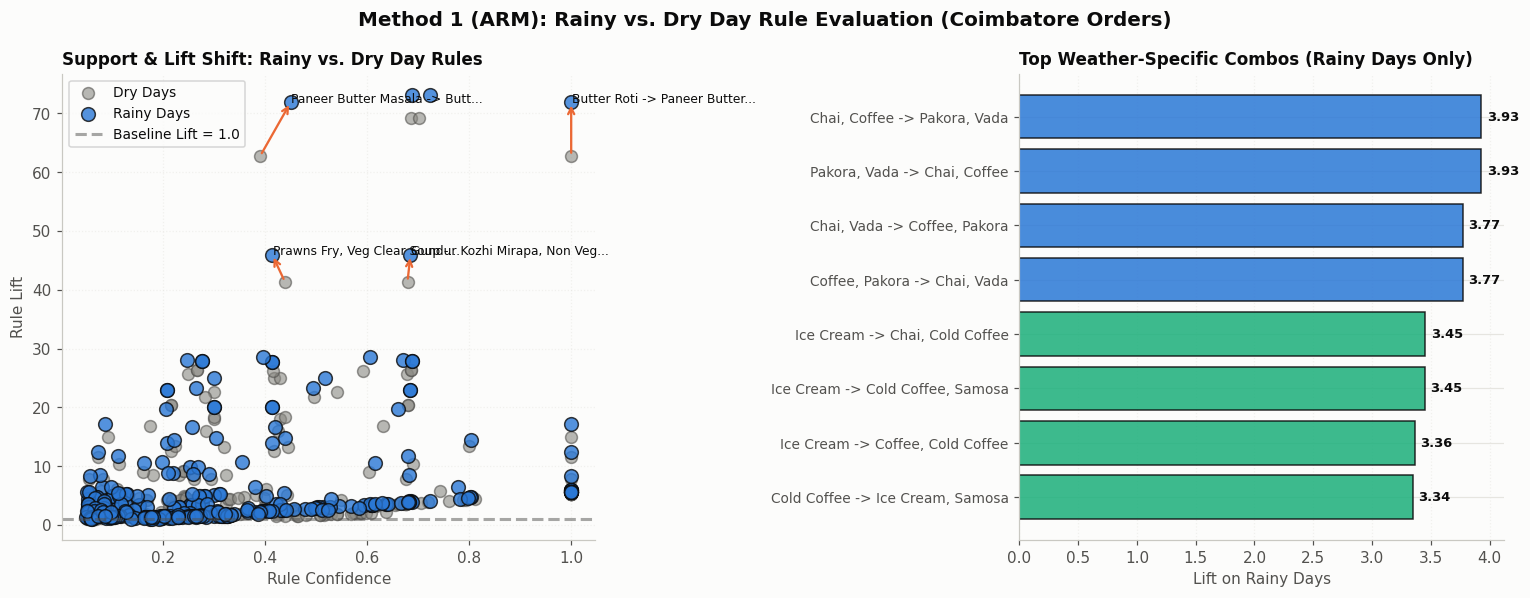

Presentation figure saved to: D:\academics\business_analytics_assingments\weather-food-orders\results\fig14_arm_rain_vs_dry.png


In [10]:
results_dir = ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

fig14_path = results_dir / "fig14_arm_rain_vs_dry.png"
fig14 = ARM.plot_rainy_vs_dry_evaluation(common_df, rainy_only_df, save_path=fig14_path)
plt.show()
print(f"Presentation figure saved to: {fig14_path}")

---
## 4. T12: Rule Threshold Sensitivity Analysis

### 4.1 Grid Evaluation across Support and Confidence
We systematically assess the stability and count of discovered rules across a 2-dimensional parameter grid:
- **Minimum Support Thresholds:** $min\_support \in [0.004, 0.006, 0.008, 0.010, 0.015]$
- **Minimum Confidence Thresholds:** $min\_confidence \in [0.02, 0.05, 0.10, 0.15, 0.20]$

In [11]:
supports = [0.004, 0.006, 0.008, 0.010, 0.015]
confidences = [0.02, 0.05, 0.10, 0.15, 0.20]

sensitivity_df, pivot_counts, pivot_max_lift = ARM.evaluate_threshold_sensitivity(
    encoded_df, support_grid=supports, confidence_grid=confidences, algorithm="fpgrowth"
)

display(HTML("<h4>Table 1: Association Rule Counts Matrix (Support x Confidence)</h4>"))
display(pivot_counts.style.background_gradient(cmap="Blues", axis=None))

min_confidence,0.020000,0.050000,0.100000,0.150000,0.200000
min_support,,,,,
0.004000,533,458,353,286,238
0.006000,398,352,282,234,198
0.008000,232,221,177,136,105
0.010000,200,192,158,120,90
0.015000,80,80,76,64,43


### 4.2 Sensitivity Visualizations: Heatmap and Decay Curves (Fig 15)
We generate presentation figure **Fig 15** (`results/fig15_arm_threshold_sensitivity.png`), illustrating parameter decay curves and rule count densities.

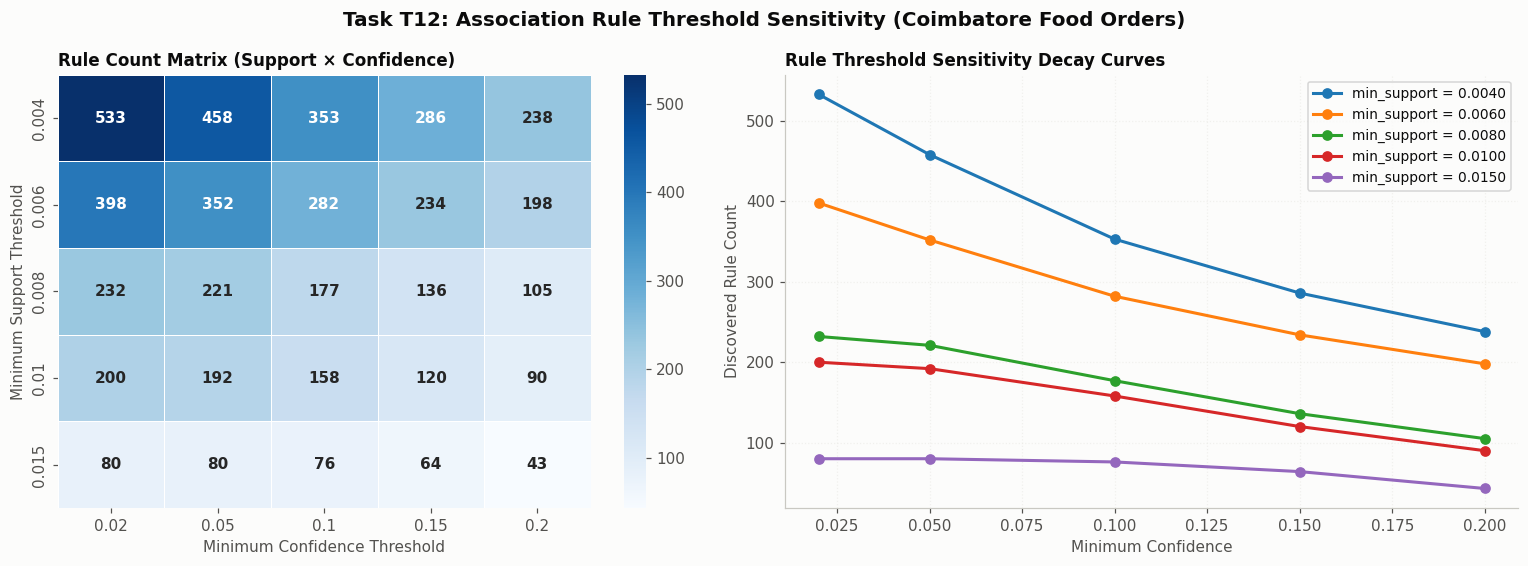

Sensitivity figure saved to: D:\academics\business_analytics_assingments\weather-food-orders\results\fig15_arm_threshold_sensitivity.png


In [12]:
fig15_path = results_dir / "fig15_arm_threshold_sensitivity.png"
fig15 = ARM.plot_threshold_sensitivity_grid(sensitivity_df, save_path=fig15_path)
plt.show()
print(f"Sensitivity figure saved to: {fig15_path}")

---
## 5. Artifact Exports and Dashboard Deliverables
We export all generated rule tables and evaluation summaries to `results/` for downstream integration with the Streamlit dashboard (P4 / T23) and monsoon lift tracking (P5 / T27).

In [13]:
# Export rule catalogs and sensitivity summaries
rules_overall.to_csv(results_dir / "rules_overall.csv", index=False)
rules_rain.to_csv(results_dir / "rules_rainy.csv", index=False)
rules_dry.to_csv(results_dir / "rules_dry.csv", index=False)
if not common_df.empty:
    common_df.to_csv(results_dir / "rules_rain_vs_dry_comparison.csv", index=False)
sensitivity_df.to_csv(results_dir / "rule_sensitivity_grid.csv", index=False)

print("=" * 80)
print("Notebook 06 (ARM & Weather-Segmented Rule Evaluation) complete.")
print("Artifacts generated in results/:")
print(f"  - {results_dir / 'rules_overall.csv'}")
print(f"  - {results_dir / 'rules_rainy.csv'}")
print(f"  - {results_dir / 'rules_dry.csv'}")
print(f"  - {results_dir / 'rules_rain_vs_dry_comparison.csv'}")
print(f"  - {results_dir / 'rule_sensitivity_grid.csv'}")
print(f"  - {results_dir / 'fig14_arm_rain_vs_dry.png'}")
print(f"  - {results_dir / 'fig15_arm_threshold_sensitivity.png'}")
print("=" * 80)

Notebook 06 (ARM & Weather-Segmented Rule Evaluation) complete.
Artifacts generated in results/:
  - D:\academics\business_analytics_assingments\weather-food-orders\results\rules_overall.csv
  - D:\academics\business_analytics_assingments\weather-food-orders\results\rules_rainy.csv
  - D:\academics\business_analytics_assingments\weather-food-orders\results\rules_dry.csv
  - D:\academics\business_analytics_assingments\weather-food-orders\results\rules_rain_vs_dry_comparison.csv
  - D:\academics\business_analytics_assingments\weather-food-orders\results\rule_sensitivity_grid.csv
  - D:\academics\business_analytics_assingments\weather-food-orders\results\fig14_arm_rain_vs_dry.png
  - D:\academics\business_analytics_assingments\weather-food-orders\results\fig15_arm_threshold_sensitivity.png
